# Deep Learning Practical Exam - Set C

Five mini-projects: ANN, OpenCV, CNN, RNN and Transformers.

# Step 1: ANN - Wine Cultivar Classification

## 1.1 Data Loading and Preprocessing

In [1]:
import pandas as pd
from sklearn.datasets import load_wine

data = load_wine(as_frame=True)
df = data.frame

In [2]:
print("Shape:", df.shape)

Shape: (178, 14)


In [3]:
df.head(5)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print(df.isnull().sum())

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


In [5]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


### Class distribution

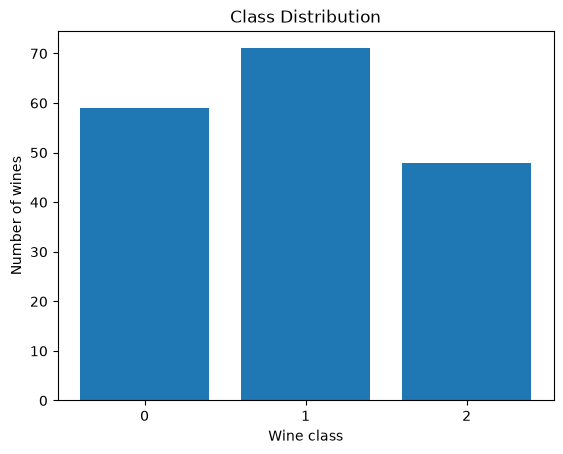

In [6]:
import matplotlib.pyplot as plt

class_counts = df['target'].value_counts().sort_index()

plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel("Wine class")
plt.ylabel("Number of wines")
plt.title("Class Distribution")
plt.show()

**Interpretation**
- Class 1 has the most wines and class 2 has the fewest.
- The difference is small, so the data is fairly balanced and accuracy is a fair metric.

### Feature ranges

In [7]:
features = df.drop(columns='target')
feature_range = features.max() - features.min()

big = feature_range.idxmax()
small = feature_range.idxmin()

print("Largest range :", big, "->", features[big].min(), "to", features[big].max())
print("Smallest range:", small, "->", features[small].min(), "to", features[small].max())

Largest range : proline -> 278.0 to 1680.0
Smallest range: nonflavanoid_phenols -> 0.13 to 0.66


**Interpretation**
- `proline` has a very large range, while `nonflavanoid_phenols` has a very small range.
- A neural network gives more weight to big numbers, so proline would dominate the learning.
- Scaling puts all features on the same level, so every feature gets a fair chance.

### Features, target and train-test split

In [8]:
X = df.drop(columns='target')
y = df['target']
print(X.shape, y.shape)

(178, 13) (178,)


In [9]:
from sklearn.model_selection import train_test_split

seed = 42
test_size = 0.2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=seed, stratify=y)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (142, 13)
Test : (36, 13)


### Scaling

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### One-hot encoding

In [11]:
from tensorflow.keras.utils import to_categorical

num_classes = y.nunique()

y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_test_cat = to_categorical(y_test, num_classes=num_classes)

print(y_train_cat[:3])

[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]


## 1.2 Build the ANN

In [12]:
from tensorflow.keras.utils import set_random_seed
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

set_random_seed(seed)
num_features = X_train_scaled.shape[1]

In [13]:
ann_model = Sequential()
ann_model.add(Input(shape=(num_features,)))
ann_model.add(Dense(16, activation='relu'))
ann_model.add(Dense(8, activation='relu'))
ann_model.add(Dense(num_classes, activation='softmax'))

In [14]:
ann_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [15]:
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 387 (1.51 KB)

 Trainable params: 387 (1.51 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
inputs = num_features
neurons = 16

print("Weights:", inputs * neurons)
print("Biases :", neurons)
print("Total  :", inputs * neurons + neurons)

Weights: 208
Biases : 16
Total  : 224


**Hand check of the first hidden layer**
- Inputs = 13 and neurons = 16
- Weights = 13 x 16 = 208
- Biases = 16 (one per neuron)
- Total = 208 + 16 = **224**, which matches `model.summary()`

## 1.3 Train and Evaluate

In [17]:
epochs = 60
batch_size = 8

history = ann_model.fit(X_train_scaled, y_train_cat,
                        epochs=epochs,
                        batch_size=batch_size,
                        validation_split=0.2,
                        verbose=0)

In [18]:
print("Final train accuracy:", round(history.history['accuracy'][-1], 4))
print("Final val accuracy  :", round(history.history['val_accuracy'][-1], 4))

Final train accuracy: 1.0
Final val accuracy  : 1.0


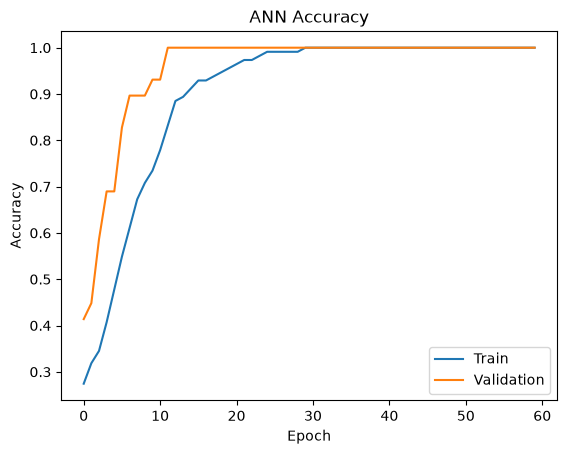

In [19]:
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN Accuracy")
plt.legend()
plt.show()

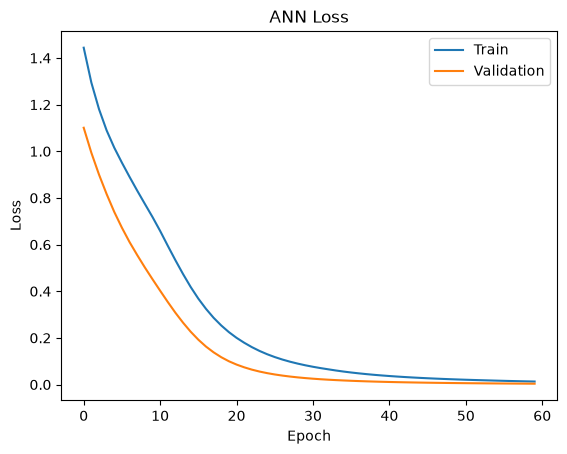

In [20]:
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Loss")
plt.legend()
plt.show()

**Interpretation**
- Accuracy rises very fast in the first few epochs and then stays high.
- Loss falls and stays low, and the train and validation lines stay close.
- The validation loss does not go up again, so there is no strong overfitting and Dropout is not needed.

### Predictions on the test set

In [21]:
import numpy as np

y_pred_prob = ann_model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


In [22]:
from sklearn.metrics import accuracy_score

ann_test_accuracy = accuracy_score(y_test, y_pred)
print("Test Accuracy:", round(ann_test_accuracy * 100, 2), "%")

Test Accuracy: 94.44 %


In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=data.target_names))

              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       0.93      0.93      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



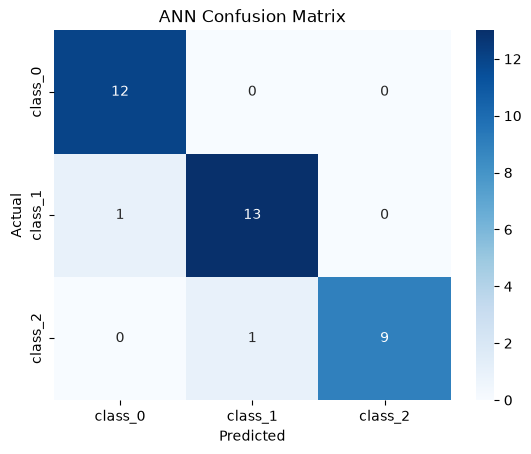

In [24]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ANN Confusion Matrix")
plt.show()

**Interpretation**
- Test accuracy is around the 94% target. One wrong wine changes it by about 2.8%, so small differences are normal.
- Precision, recall and F1 are high for all three classes.
- Almost all wines are on the diagonal of the heatmap, so only a few wines are predicted wrongly.

## 1.4 Save and Reflect

In [25]:
ann_model.save('models/ann_wine_model.h5')

In [26]:
print("Probabilities of first test wine:", y_pred_prob[0])
print("Sum of the 3 outputs:", y_pred_prob[0].sum())

Probabilities of first test wine: [9.9969602e-01 2.7402103e-04 3.0084781e-05]
Sum of the 3 outputs: 1.0000001


**Reflection**
- Input layer takes the 13 scaled chemical values.
- Hidden layer 1 (16 neurons, ReLU) learns simple patterns from the inputs.
- Hidden layer 2 (8 neurons, ReLU) joins those patterns into stronger ones.
- Output layer (3 neurons, Softmax) gives one probability for each wine class.
- Softmax is used instead of Sigmoid because only one class is correct. Softmax makes the outputs compete, while Sigmoid treats every output separately.
- Categorical crossentropy compares the predicted probabilities with the one-hot label and gives a big penalty for confident wrong answers. It is made for multi-class one-hot targets.
- The 3 output numbers always add up to 1.

# Step 2: OpenCV - Colour, Morphology and Face Detection

## 2.1 Load and Display

In [27]:
import cv2
from skimage import data as skdata

loaders = [skdata.astronaut, skdata.coffee, skdata.chelsea, skdata.rocket, skdata.colorwheel]
names = [loader.__name__ for loader in loaders]
print(names)

['astronaut', 'coffee', 'chelsea', 'rocket', 'colorwheel']


In [28]:
images = []

for loader in loaders:
    img = loader()
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    images.append(img)

print("Images loaded:", len(images))

Images loaded: 5


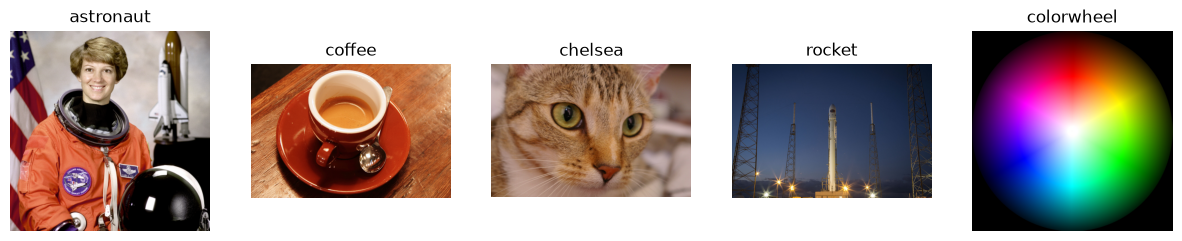

In [29]:
plt.figure(figsize=(15, 3))

for i in range(len(images)):
    plt.subplot(1, len(images), i + 1)
    plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
    plt.title(names[i])
    plt.axis('off')

plt.show()

In [30]:
for i in range(len(images)):
    img = images[i]
    print(names[i], "| shape:", img.shape, "| dtype:", img.dtype,
          "| min:", img.min(), "| max:", img.max(), "| mean:", round(img.mean(), 2))

astronaut | shape: (512, 512, 3) | dtype: uint8 | min: 0 | max: 255 | mean: 114.6
coffee | shape: (400, 600, 3) | dtype: uint8 | min: 0 | max: 255 | mean: 98.62
chelsea | shape: (300, 451, 3) | dtype: uint8 | min: 0 | max: 231 | mean: 115.31
rocket | shape: (427, 640, 3) | dtype: uint8 | min: 0 | max: 255 | mean: 65.28
colorwheel | shape: (370, 371, 3) | dtype: uint8 | min: 0 | max: 255 | mean: 76.33


## 2.2 Preprocessing Operations

### Resize

In [31]:
size = 256
resized = []

for img in images:
    resized.append(cv2.resize(img, (size, size)))

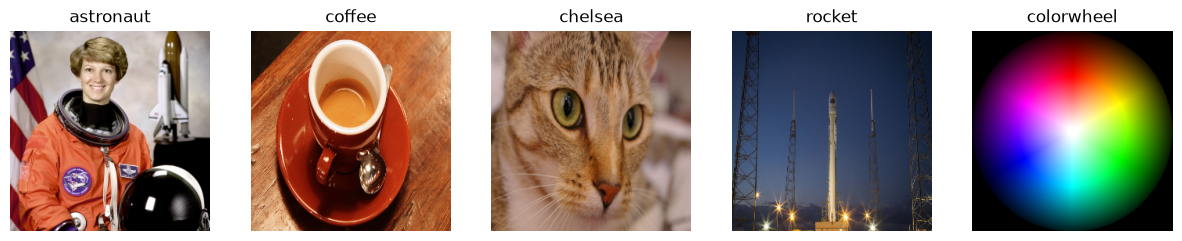

In [32]:
plt.figure(figsize=(15, 3))

for i in range(len(resized)):
    plt.subplot(1, len(resized), i + 1)
    plt.imshow(cv2.cvtColor(resized[i], cv2.COLOR_BGR2RGB))
    plt.title(names[i])
    plt.axis('off')

plt.show()

### HSV conversion

In [33]:
hsv_images = []

for img in resized:
    hsv_images.append(cv2.cvtColor(img, cv2.COLOR_BGR2HSV))

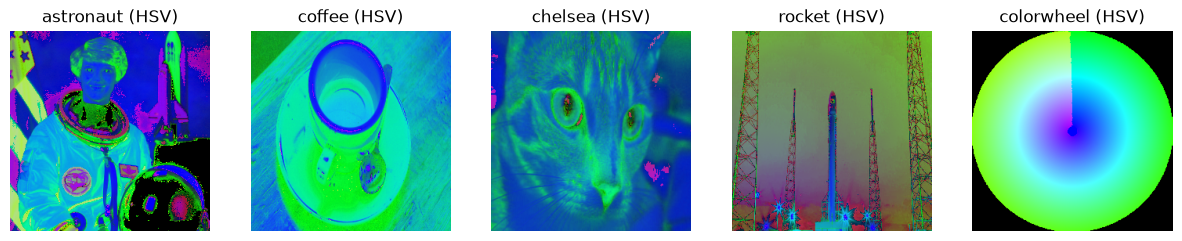

In [34]:
plt.figure(figsize=(15, 3))

for i in range(len(hsv_images)):
    plt.subplot(1, len(hsv_images), i + 1)
    plt.imshow(hsv_images[i])
    plt.title(names[i] + " (HSV)")
    plt.axis('off')

plt.show()

### Colour mask (orange)

In [35]:
lower_orange = np.array([10, 100, 70])
upper_orange = np.array([25, 255, 255])

masks = []
colour_only = []

for i in range(len(resized)):
    mask = cv2.inRange(hsv_images[i], lower_orange, upper_orange)
    result = cv2.bitwise_and(resized[i], resized[i], mask=mask)
    masks.append(mask)
    colour_only.append(result)

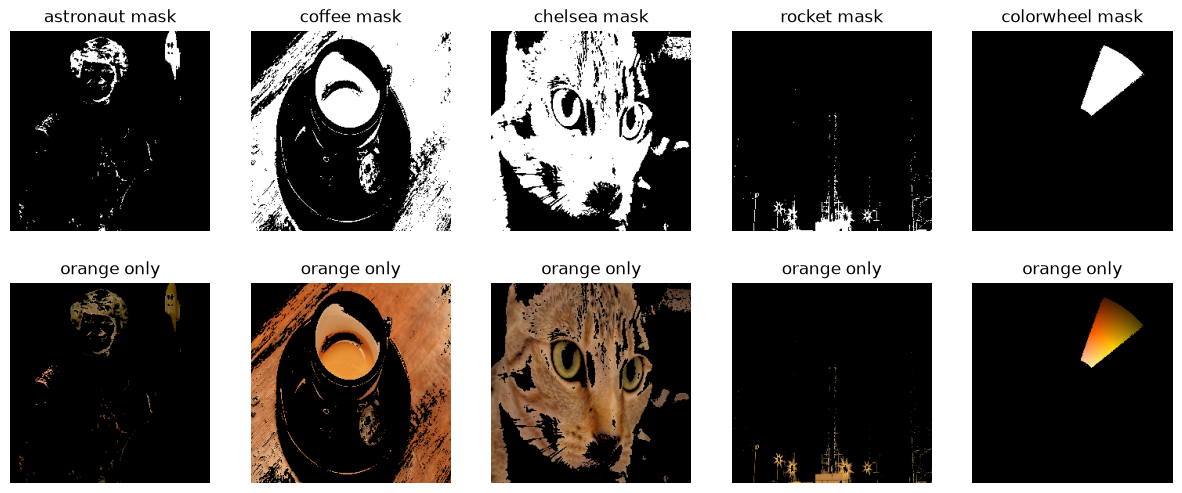

In [36]:
plt.figure(figsize=(15, 6))

for i in range(len(masks)):
    plt.subplot(2, len(masks), i + 1)
    plt.imshow(masks[i], cmap='gray')
    plt.title(names[i] + " mask")
    plt.axis('off')

    plt.subplot(2, len(masks), len(masks) + i + 1)
    plt.imshow(cv2.cvtColor(colour_only[i], cv2.COLOR_BGR2RGB))
    plt.title("orange only")
    plt.axis('off')

plt.show()

### Clean the mask (erode then dilate)

In [37]:
kernel = np.ones((5, 5), np.uint8)
clean_masks = []

for mask in masks:
    eroded = cv2.erode(mask, kernel)
    cleaned = cv2.dilate(eroded, kernel)
    clean_masks.append(cleaned)

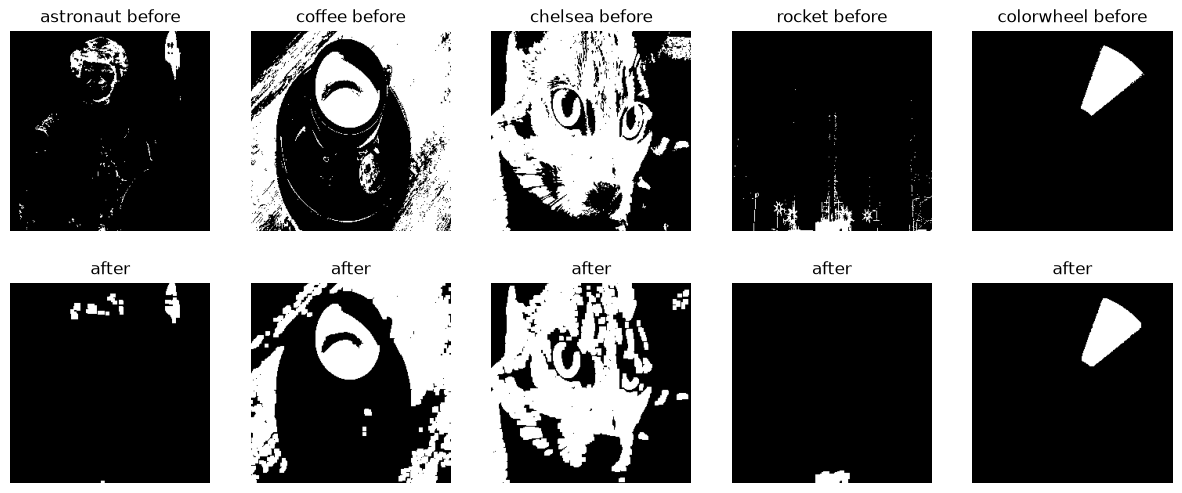

In [38]:
plt.figure(figsize=(15, 6))

for i in range(len(masks)):
    plt.subplot(2, len(masks), i + 1)
    plt.imshow(masks[i], cmap='gray')
    plt.title(names[i] + " before")
    plt.axis('off')

    plt.subplot(2, len(masks), len(masks) + i + 1)
    plt.imshow(clean_masks[i], cmap='gray')
    plt.title("after")
    plt.axis('off')

plt.show()

### Sobel edge detection

In [39]:
sobel_images = []

for img in resized:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1)
    combined = np.sqrt(sobel_x ** 2 + sobel_y ** 2)
    sobel_images.append(cv2.convertScaleAbs(combined))

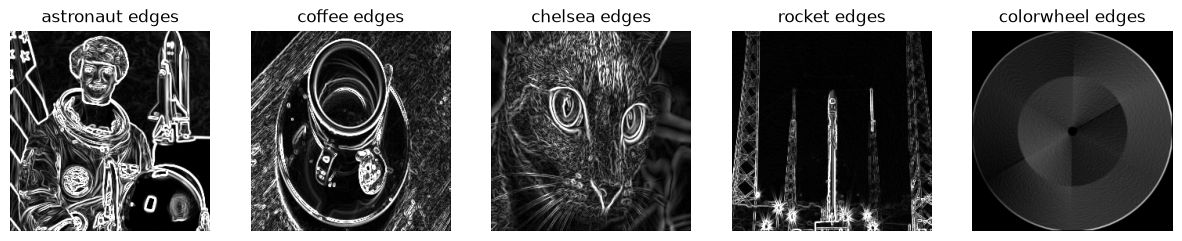

In [40]:
plt.figure(figsize=(15, 3))

for i in range(len(sobel_images)):
    plt.subplot(1, len(sobel_images), i + 1)
    plt.imshow(sobel_images[i], cmap='gray')
    plt.title(names[i] + " edges")
    plt.axis('off')

plt.show()

**Interpretation**
- The orange mask keeps the orange parts: most of the coffee and cat images, and very little of the rocket image.
- Erode then dilate removes the small white dots (noise) and keeps the main shapes.
- Sobel edges are bright where the brightness changes quickly, such as object borders.

## 2.3 Face Detection with Haar Cascade

In [41]:
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

In [42]:
scale_factor = 1.1
min_neighbors = 5

face_images = []
face_counts = []

for i in range(len(resized)):
    gray = cv2.cvtColor(resized[i], cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=scale_factor, minNeighbors=min_neighbors)

    drawn = resized[i].copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(drawn, (x, y), (x + w, y + h), (255, 0, 0), 2)
        cv2.putText(drawn, "Face", (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)

    face_images.append(drawn)
    face_counts.append(len(faces))
    print(names[i], "-> faces found:", len(faces))

astronaut -> faces found: 1
coffee -> faces found: 0
chelsea -> faces found: 0
rocket -> faces found: 0
colorwheel -> faces found: 0


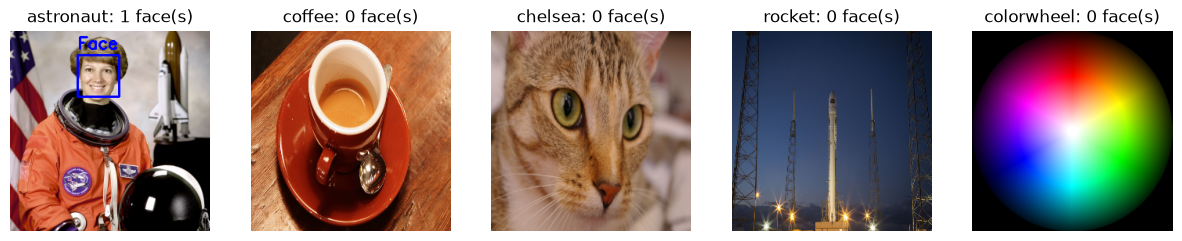

In [43]:
plt.figure(figsize=(15, 3))

for i in range(len(face_images)):
    plt.subplot(1, len(face_images), i + 1)
    plt.imshow(cv2.cvtColor(face_images[i], cv2.COLOR_BGR2RGB))
    plt.title(names[i] + ": " + str(face_counts[i]) + " face(s)")
    plt.axis('off')

plt.show()

### Effect of minNeighbors

In [44]:
test_gray = cv2.cvtColor(resized[0], cv2.COLOR_BGR2GRAY)

for neighbors in [2, 5, 8]:
    faces = face_cascade.detectMultiScale(test_gray, scaleFactor=scale_factor, minNeighbors=neighbors)
    print("minNeighbors =", neighbors, "-> faces found in", names[0], ":", len(faces))

minNeighbors = 2 -> faces found in astronaut : 2
minNeighbors = 5 -> faces found in astronaut : 1
minNeighbors = 8 -> faces found in astronaut : 1


**Interpretation**
- Only the astronaut image has a real face, so the other images show 0 faces.
- With `minNeighbors = 2` the detector is not strict, so it gives an extra box that is not a real face (false positive).
- With `minNeighbors = 5` and `8` only the real face remains. A very high value can make the detector miss small or tilted faces.

## 2.4 Summary

In [45]:
import os

output_folder = 'outputs'
os.makedirs(output_folder, exist_ok=True)

for i in range(len(images)):
    cv2.imwrite(os.path.join(output_folder, names[i] + '_original.png'), resized[i])
    cv2.imwrite(os.path.join(output_folder, names[i] + '_hsv.png'), hsv_images[i])
    cv2.imwrite(os.path.join(output_folder, names[i] + '_colour_mask.png'), colour_only[i])
    cv2.imwrite(os.path.join(output_folder, names[i] + '_morphology.png'), clean_masks[i])
    cv2.imwrite(os.path.join(output_folder, names[i] + '_sobel.png'), sobel_images[i])
    cv2.imwrite(os.path.join(output_folder, names[i] + '_face.png'), face_images[i])

print("Saved files:", len(os.listdir(output_folder)))

Saved files: 32


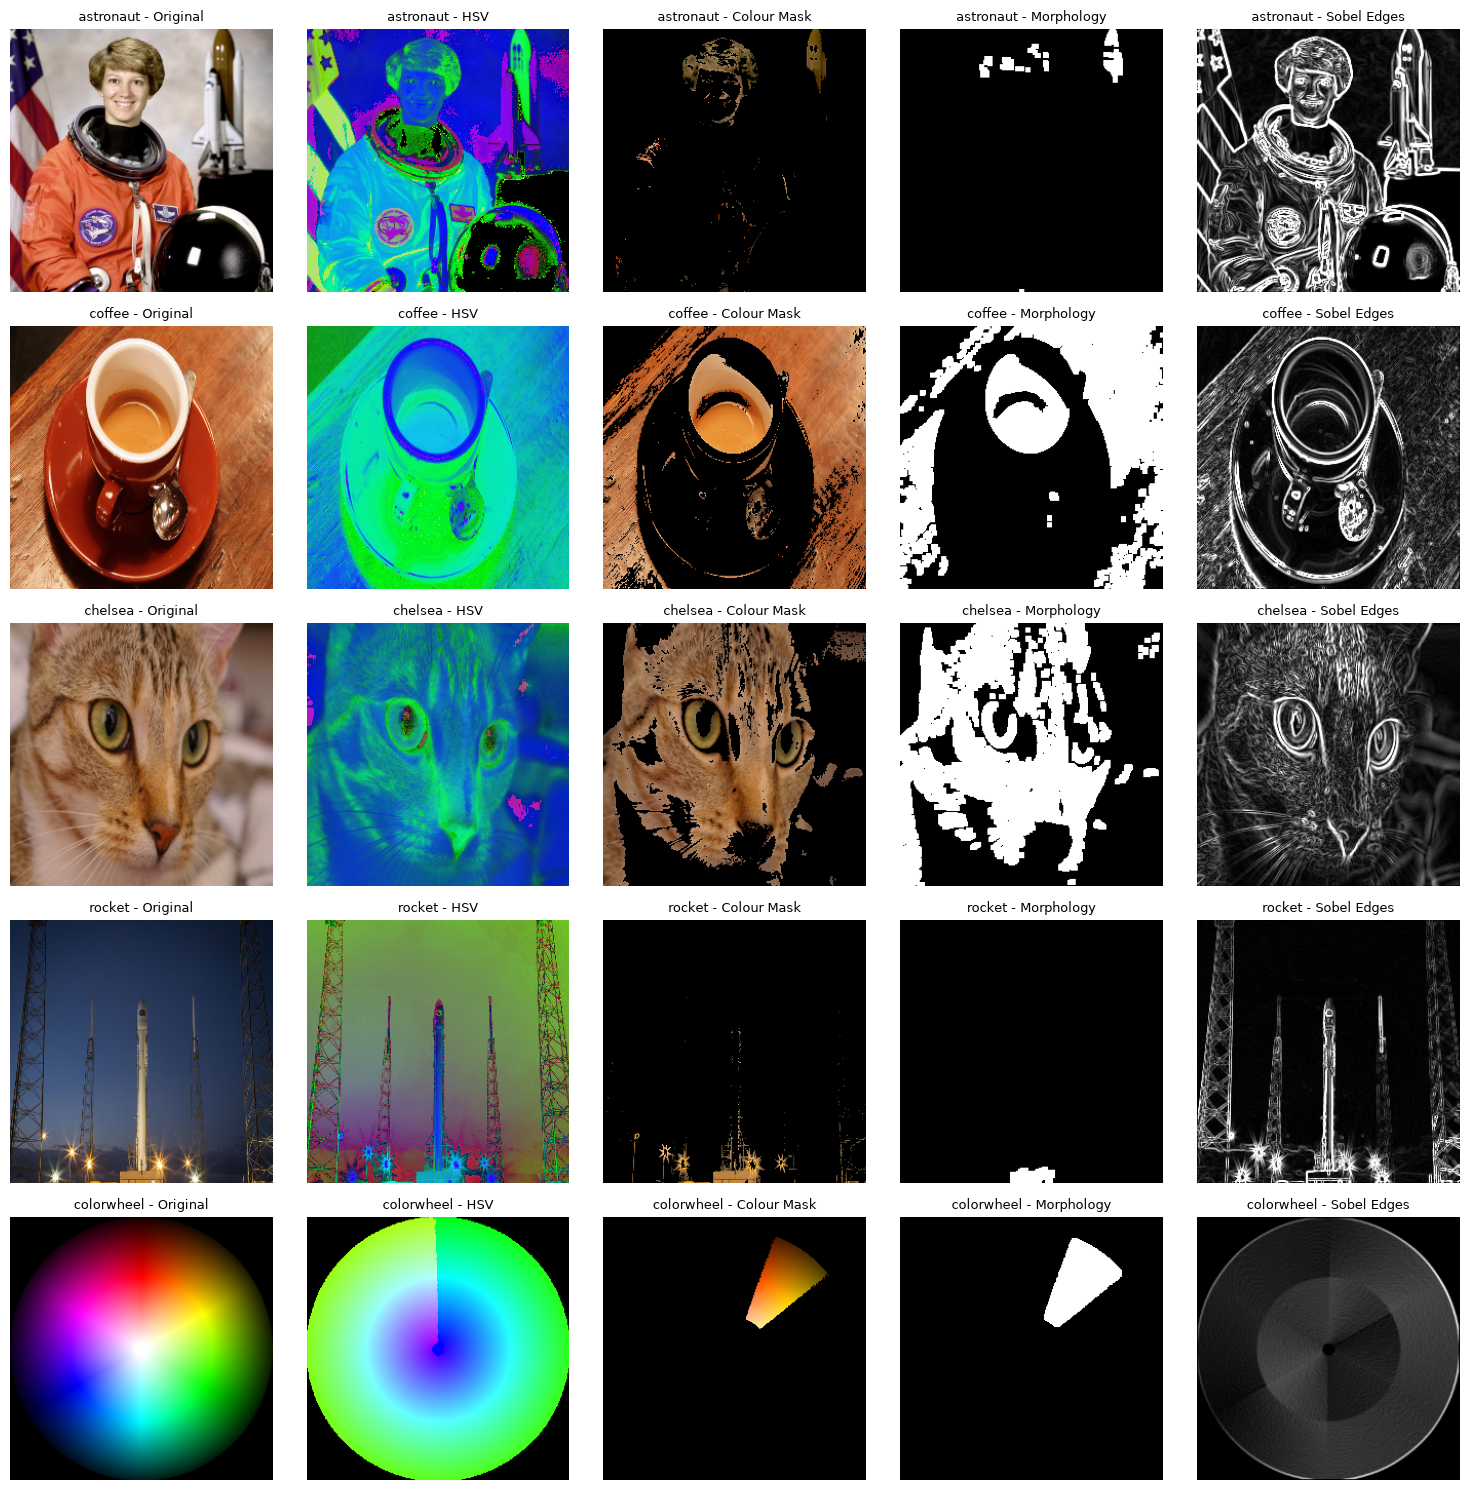

In [46]:
columns = ['Original', 'HSV', 'Colour Mask', 'Morphology', 'Sobel Edges']

fig, axes = plt.subplots(len(images), len(columns), figsize=(15, 15))

for i in range(len(images)):
    axes[i, 0].imshow(cv2.cvtColor(resized[i], cv2.COLOR_BGR2RGB))
    axes[i, 1].imshow(hsv_images[i])
    axes[i, 2].imshow(cv2.cvtColor(colour_only[i], cv2.COLOR_BGR2RGB))
    axes[i, 3].imshow(clean_masks[i], cmap='gray')
    axes[i, 4].imshow(sobel_images[i], cmap='gray')

    for j in range(len(columns)):
        axes[i, j].set_title(names[i] + " - " + columns[j], fontsize=9)
        axes[i, j].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(output_folder, 'summary_grid.png'))
plt.show()

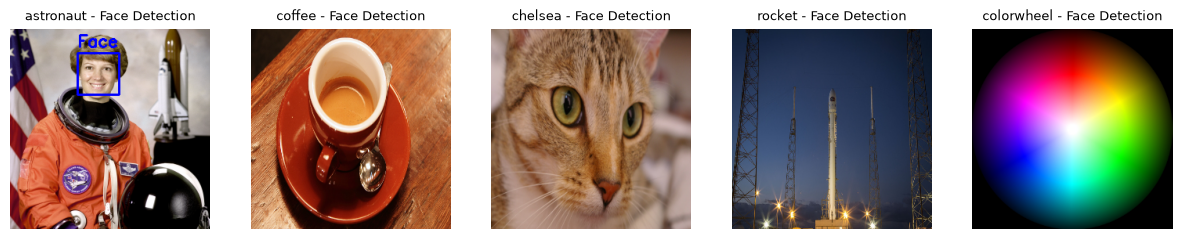

In [47]:
plt.figure(figsize=(15, 3))

for i in range(len(face_images)):
    plt.subplot(1, len(face_images), i + 1)
    plt.imshow(cv2.cvtColor(face_images[i], cv2.COLOR_BGR2RGB))
    plt.title(names[i] + " - Face Detection", fontsize=9)
    plt.axis('off')

plt.savefig(os.path.join(output_folder, 'face_detection_row.png'))
plt.show()

**Reflection**
- HSV is easier than BGR for colour selection because Hue holds only the colour, while Saturation and Value hold the strength and brightness. One Hue range picks a colour even in light or shadow, but in BGR all three channels change when the light changes.
- Erosion shrinks the white area of a mask and removes tiny noise dots. Dilation grows the white area back. Erosion followed by dilation cleans the mask but keeps the main shape.
- A Haar cascade uses hand-made features (simple light and dark patterns) with fixed rules. A CNN learns its features by itself from many images, so it usually works better on tilted or side faces.

# Step 3: CNN - Digit Recognition with MNIST

## 3.1 Data Loading and Preparation

In [48]:
from tensorflow.keras.datasets import mnist

(img_train, label_train), (img_test, label_test) = mnist.load_data()
print(img_train.shape, img_test.shape)

(60000, 28, 28) (10000, 28, 28)


In [49]:
train_samples = 20000
test_samples = 4000

img_train = img_train[:train_samples]
label_train = label_train[:train_samples]
img_test = img_test[:test_samples]
label_test = label_test[:test_samples]

print(img_train.shape, img_test.shape)

(20000, 28, 28) (4000, 28, 28)


In [50]:
img_train = img_train / 255.0
img_test = img_test / 255.0

height = img_train.shape[1]
width = img_train.shape[2]

img_train = img_train.reshape(len(img_train), height, width, 1)
img_test = img_test.reshape(len(img_test), height, width, 1)

print(img_train.shape, img_test.shape)

(20000, 28, 28, 1) (4000, 28, 28, 1)


In [51]:
num_digits = len(np.unique(label_train))

label_train_cat = to_categorical(label_train, num_digits)
label_test_cat = to_categorical(label_test, num_digits)

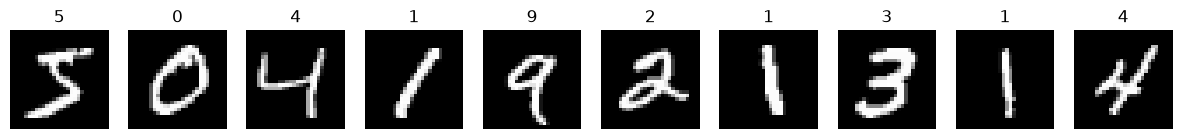

In [52]:
plt.figure(figsize=(15, 2))

for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(img_train[i].reshape(height, width), cmap='gray')
    plt.title(label_train[i])
    plt.axis('off')

plt.show()

## 3.2 Build the CNN and the ANN Baseline

In [53]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten

set_random_seed(seed)
input_shape = img_train.shape[1:]

In [54]:
cnn_model = Sequential()
cnn_model.add(Input(shape=input_shape))
cnn_model.add(Conv2D(16, (3, 3), activation='relu'))
cnn_model.add(MaxPooling2D(2, 2))
cnn_model.add(Conv2D(32, (3, 3), activation='relu'))
cnn_model.add(MaxPooling2D(2, 2))
cnn_model.add(Flatten())
cnn_model.add(Dense(64, activation='relu'))
cnn_model.add(Dense(num_digits, activation='softmax'))

In [55]:
ann_mnist_model = Sequential()
ann_mnist_model.add(Input(shape=input_shape))
ann_mnist_model.add(Flatten())
ann_mnist_model.add(Dense(128, activation='relu'))
ann_mnist_model.add(Dense(64, activation='relu'))
ann_mnist_model.add(Dense(num_digits, activation='softmax'))

In [56]:
cnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
ann_mnist_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [57]:
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 16)          │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 800)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │          51,264 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

In [58]:
ann_mnist_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [59]:
cnn_params = cnn_model.count_params()
ann_params = ann_mnist_model.count_params()

print("CNN total parameters:", cnn_params)
print("ANN total parameters:", ann_params)

CNN total parameters: 56714
ANN total parameters: 109386


## 3.3 Train and Evaluate

In [60]:
from tensorflow.keras.callbacks import EarlyStopping

epochs = 8
batch_size = 64
validation_split = 0.1

early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

In [61]:
cnn_history = cnn_model.fit(img_train, label_train_cat,
                            epochs=epochs,
                            batch_size=batch_size,
                            validation_split=validation_split,
                            callbacks=[early_stop],
                            verbose=2)

Epoch 1/8
282/282 - 4s - 15ms/step - accuracy: 0.8578 - loss: 0.4871 - val_accuracy: 0.9600 - val_loss: 0.1313
Epoch 2/8
282/282 - 2s - 8ms/step - accuracy: 0.9617 - loss: 0.1294 - val_accuracy: 0.9750 - val_loss: 0.0952
Epoch 3/8
282/282 - 2s - 8ms/step - accuracy: 0.9729 - loss: 0.0922 - val_accuracy: 0.9795 - val_loss: 0.0826
Epoch 4/8
282/282 - 2s - 8ms/step - accuracy: 0.9784 - loss: 0.0717 - val_accuracy: 0.9830 - val_loss: 0.0723
Epoch 5/8
282/282 - 2s - 8ms/step - accuracy: 0.9813 - loss: 0.0576 - val_accuracy: 0.9830 - val_loss: 0.0675
Epoch 6/8
282/282 - 2s - 8ms/step - accuracy: 0.9857 - loss: 0.0459 - val_accuracy: 0.9820 - val_loss: 0.0663
Epoch 7/8
282/282 - 2s - 8ms/step - accuracy: 0.9886 - loss: 0.0379 - val_accuracy: 0.9810 - val_loss: 0.0679
Epoch 8/8
282/282 - 2s - 9ms/step - accuracy: 0.9908 - loss: 0.0310 - val_accuracy: 0.9810 - val_loss: 0.0710


In [62]:
ann_history = ann_mnist_model.fit(img_train, label_train_cat,
                                  epochs=epochs,
                                  batch_size=batch_size,
                                  validation_split=validation_split,
                                  verbose=2)

Epoch 1/8
282/282 - 2s - 8ms/step - accuracy: 0.8670 - loss: 0.4738 - val_accuracy: 0.9425 - val_loss: 0.2194
Epoch 2/8
282/282 - 1s - 3ms/step - accuracy: 0.9434 - loss: 0.1961 - val_accuracy: 0.9525 - val_loss: 0.1742
Epoch 3/8
282/282 - 1s - 4ms/step - accuracy: 0.9614 - loss: 0.1339 - val_accuracy: 0.9595 - val_loss: 0.1480
Epoch 4/8
282/282 - 1s - 3ms/step - accuracy: 0.9731 - loss: 0.0967 - val_accuracy: 0.9615 - val_loss: 0.1388
Epoch 5/8
282/282 - 1s - 3ms/step - accuracy: 0.9792 - loss: 0.0725 - val_accuracy: 0.9655 - val_loss: 0.1318
Epoch 6/8
282/282 - 1s - 3ms/step - accuracy: 0.9848 - loss: 0.0542 - val_accuracy: 0.9630 - val_loss: 0.1361
Epoch 7/8
282/282 - 1s - 4ms/step - accuracy: 0.9896 - loss: 0.0401 - val_accuracy: 0.9605 - val_loss: 0.1467
Epoch 8/8
282/282 - 1s - 5ms/step - accuracy: 0.9928 - loss: 0.0303 - val_accuracy: 0.9625 - val_loss: 0.1517


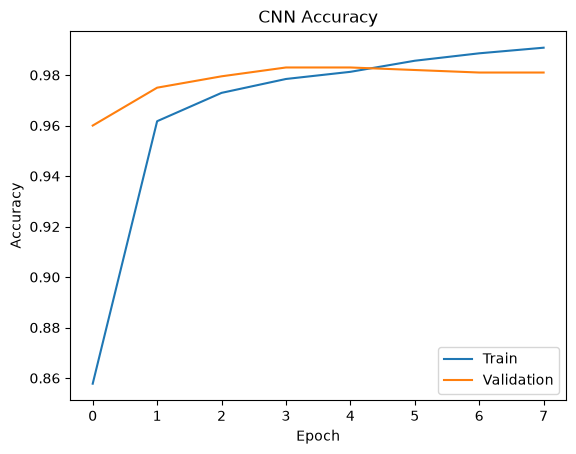

In [63]:
plt.plot(cnn_history.history['accuracy'], label='Train')
plt.plot(cnn_history.history['val_accuracy'], label='Validation')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.show()

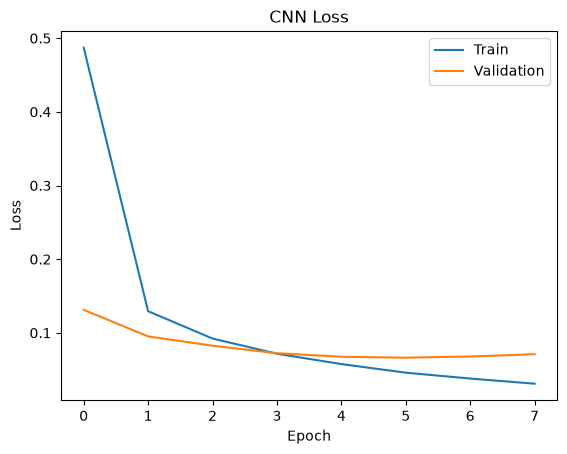

In [64]:
plt.plot(cnn_history.history['loss'], label='Train')
plt.plot(cnn_history.history['val_loss'], label='Validation')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.show()

**Interpretation**
- Accuracy goes up quickly in the first epochs and then becomes almost flat.
- Training loss keeps falling, while validation loss falls and then becomes flat or rises a little.
- EarlyStopping keeps the weights from the best validation epoch, so the CNN does not overfit.

### CNN vs ANN

In [65]:
cnn_loss, cnn_acc = cnn_model.evaluate(img_test, label_test_cat, verbose=0)
ann_loss, ann_acc = ann_mnist_model.evaluate(img_test, label_test_cat, verbose=0)

In [66]:
comparison = pd.DataFrame({
    'Model': ['CNN', 'ANN'],
    'Total Parameters': [cnn_params, ann_params],
    'Test Accuracy': [round(cnn_acc, 4), round(ann_acc, 4)]
})

comparison

,Model,Total Parameters,Test Accuracy
0,CNN,56714,0.9728
1,ANN,109386,0.9545


**Interpretation**
- Both models score high on MNIST because digits are easy to learn.
- The CNN is usually more accurate than the ANN, and it uses about half the parameters (56,714 vs 109,386).

### CNN predictions

In [67]:
cnn_pred = np.argmax(cnn_model.predict(img_test), axis=1)

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [68]:
print(classification_report(label_test, cnn_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       370
           1       0.98      0.99      0.99       450
           2       0.96      0.98      0.97       418
           3       0.94      0.99      0.96       408
           4       0.97      0.99      0.98       418
           5       0.94      0.99      0.96       372
           6       0.99      0.96      0.98       378
           7       0.99      0.95      0.97       411
           8       0.97      0.96      0.97       384
           9       0.99      0.94      0.96       391

    accuracy                           0.97      4000
   macro avg       0.97      0.97      0.97      4000
weighted avg       0.97      0.97      0.97      4000



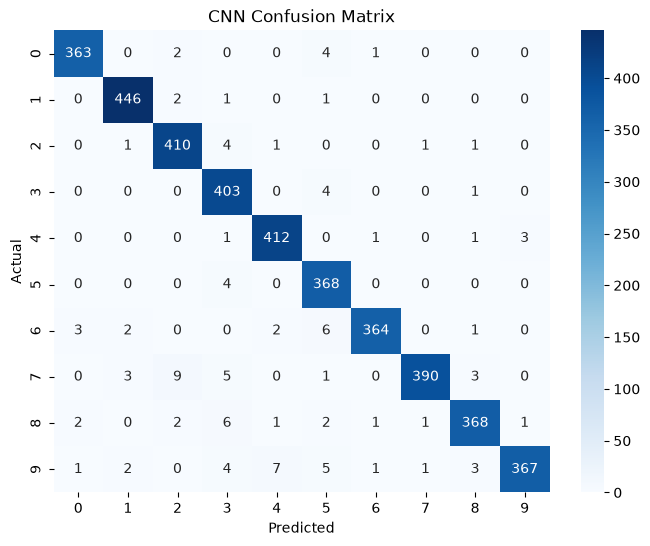

In [69]:
cm_cnn = confusion_matrix(label_test, cnn_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")
plt.show()

In [70]:
errors = cm_cnn.copy()
np.fill_diagonal(errors, 0)

worst = np.unravel_index(errors.argmax(), errors.shape)
print("Most confused: true", worst[0], "predicted as", worst[1], "->", errors.max(), "times")

Most confused: true 7 predicted as 2 -> 9 times


**Interpretation**
- Precision and recall are high for all 10 digits.
- The diagonal of the heatmap is very dark, and the few errors are spread over a small number of digit pairs.

### Wrong predictions

In [71]:
wrong_index = np.where(cnn_pred != label_test)[0]
print("Total wrong predictions:", len(wrong_index))

Total wrong predictions: 109


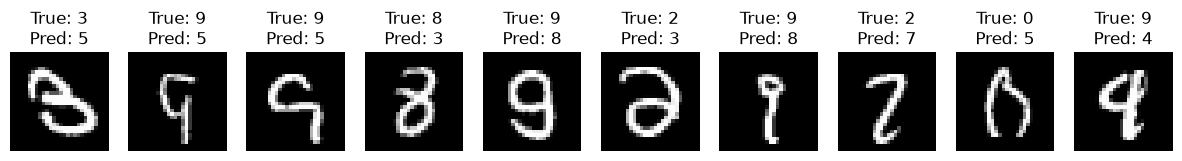

In [72]:
show_index = wrong_index[:10]

plt.figure(figsize=(15, 3))

for i in range(len(show_index)):
    idx = show_index[i]
    plt.subplot(1, len(show_index), i + 1)
    plt.imshow(img_test[idx].reshape(height, width), cmap='gray')
    plt.title("True: " + str(label_test[idx]) + "\nPred: " + str(cnn_pred[idx]))
    plt.axis('off')

plt.show()

**Interpretation**
- Most wrong digits are written in an unclear or unusual way, so even a person can find them hard to read.

### Feature maps

In [73]:
from tensorflow.keras.models import Model

feature_model = Model(inputs=cnn_model.inputs, outputs=cnn_model.layers[0].output)

sample = img_test[:1]
feature_maps = feature_model.predict(sample)
print(feature_maps.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
(1, 26, 26, 16)


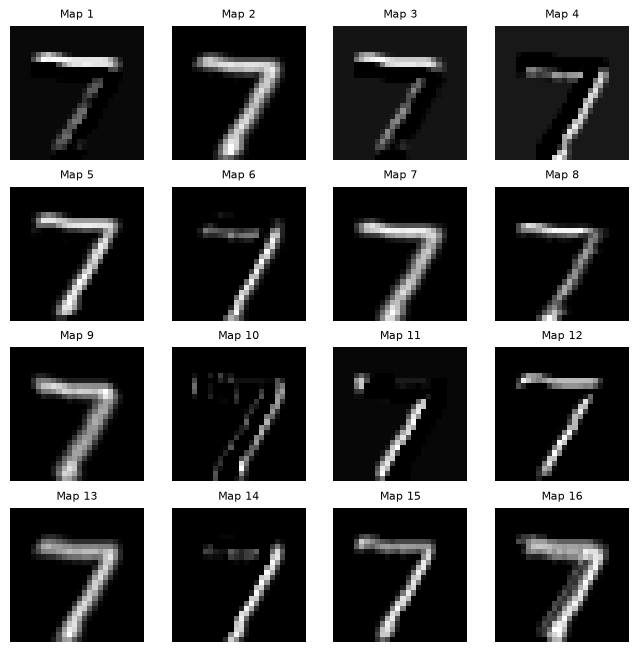

In [74]:
num_maps = feature_maps.shape[-1]
grid = int(np.sqrt(num_maps))

plt.figure(figsize=(8, 8))

for i in range(num_maps):
    plt.subplot(grid, grid, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='gray')
    plt.title("Map " + str(i + 1), fontsize=8)
    plt.axis('off')

plt.show()

**Interpretation**
- Each map comes from one filter of the first Conv2D layer.
- Some maps highlight edges of the digit, some highlight strokes in one direction, and some show the whole digit shape.

## 3.4 Save and Reflect

In [75]:
cnn_model.save('models/cnn_mnist_model.h5')

**Reflection**
- Feature maps show what each filter finds in the image: edges, strokes and shapes of the digit.
- The CNN has fewer parameters because one small 3x3 filter is reused over the whole image (shared weights), while the ANN gives a separate weight to every pixel.
- MaxPooling keeps the strongest value in each 2x2 block. This makes the maps smaller, reduces parameters and makes the model less sensitive to small shifts.
- The most confused digit pair is printed above. Such digits have similar curves or strokes (for example 3, 5 and 8), so the CNN can mix them up.

# Step 4: RNN - Temperature Forecasting with GRU

## 4.1 Data Loading and Preparation

In [76]:
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'

temp_df = pd.read_csv(url, parse_dates=['Date'])

In [77]:
temp_df.head(5)

,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


In [78]:
print(temp_df.dtypes)

Date    datetime64[us]
Temp           float64
dtype: object


In [79]:
temp_df.describe()

,Date,Temp
count,3650,3650.000000
mean,1985-12-31 07:12:00,11.177753
min,1981-01-01 00:00:00,0.000000
25%,1983-07-02 06:00:00,8.300000
50%,1985-12-31 12:00:00,11.000000
75%,1988-06-30 18:00:00,14.000000
max,1990-12-31 00:00:00,26.300000
std,NaN,4.071837


### Check and clean the Temp column

In [80]:
print("Temp is numeric:", pd.api.types.is_numeric_dtype(temp_df['Temp']))

Temp is numeric: True


In [81]:
missing_before = temp_df['Temp'].isnull().sum()

temp_df['Temp'] = pd.to_numeric(temp_df['Temp'], errors='coerce')

missing_after = temp_df['Temp'].isnull().sum()
fixed = missing_after - missing_before
print("Bad values found and fixed:", fixed)

Bad values found and fixed: 0


In [82]:
temp_df['Temp'] = temp_df['Temp'].interpolate()
print("Missing values left:", temp_df['Temp'].isnull().sum())

Missing values left: 0


In [83]:
temp_df.describe()

,Date,Temp
count,3650,3650.000000
mean,1985-12-31 07:12:00,11.177753
min,1981-01-01 00:00:00,0.000000
25%,1983-07-02 06:00:00,8.300000
50%,1985-12-31 12:00:00,11.000000
75%,1988-06-30 18:00:00,14.000000
max,1990-12-31 00:00:00,26.300000
std,NaN,4.071837


### Plot the series

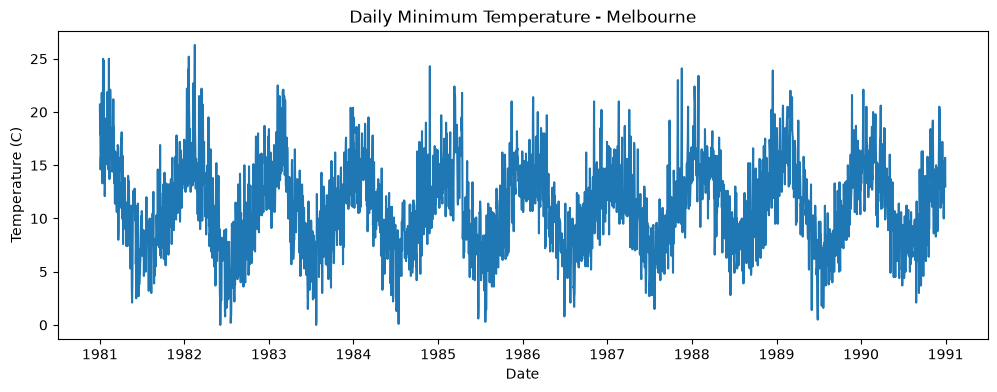

In [84]:
plt.figure(figsize=(12, 4))
plt.plot(temp_df['Date'], temp_df['Temp'])
plt.xlabel("Date")
plt.ylabel("Temperature (C)")
plt.title("Daily Minimum Temperature - Melbourne")
plt.show()

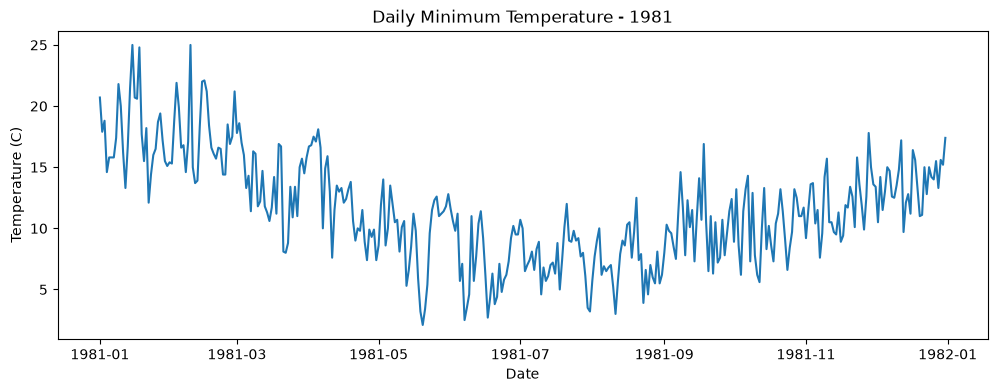

In [85]:
first_year = temp_df['Date'].dt.year.min()
one_year = temp_df[temp_df['Date'].dt.year == first_year]

plt.figure(figsize=(12, 4))
plt.plot(one_year['Date'], one_year['Temp'])
plt.xlabel("Date")
plt.ylabel("Temperature (C)")
plt.title("Daily Minimum Temperature - " + str(first_year))
plt.show()

**Interpretation**
- The full series repeats the same wave every year, so it has a clear yearly pattern.
- The one-year chart shows warm months at the start and end of the year (southern hemisphere summer) and cold months in the middle.
- Day-to-day values jump up and down, so the data is noisy.

### Train-test split and scaling

In [86]:
from sklearn.preprocessing import MinMaxScaler

temp_values = temp_df['Temp'].values.reshape(-1, 1)

split_index = int(len(temp_values) * 0.8)
train_part = temp_values[:split_index]
test_part = temp_values[split_index:]

print("Train days:", len(train_part))
print("Test days :", len(test_part))

Train days: 2920
Test days : 730


In [87]:
temp_scaler = MinMaxScaler()
train_scaled = temp_scaler.fit_transform(train_part)
test_scaled = temp_scaler.transform(test_part)

### Create sequences

In [88]:
look_back = 30

X_seq_train = []
y_seq_train = []

for i in range(look_back, len(train_scaled)):
    X_seq_train.append(train_scaled[i - look_back:i, 0])
    y_seq_train.append(train_scaled[i, 0])

In [89]:
X_seq_test = []
y_seq_test = []

for i in range(look_back, len(test_scaled)):
    X_seq_test.append(test_scaled[i - look_back:i, 0])
    y_seq_test.append(test_scaled[i, 0])

In [90]:
X_seq_train = np.array(X_seq_train)
y_seq_train = np.array(y_seq_train)
X_seq_test = np.array(X_seq_test)
y_seq_test = np.array(y_seq_test)

X_seq_train = X_seq_train.reshape(len(X_seq_train), look_back, 1)
X_seq_test = X_seq_test.reshape(len(X_seq_test), look_back, 1)

In [91]:
print("X_train:", X_seq_train.shape)
print("y_train:", y_seq_train.shape)
print("X_test :", X_seq_test.shape)
print("y_test :", y_seq_test.shape)

X_train: (2890, 30, 1)
y_train: (2890,)
X_test : (700, 30, 1)
y_test : (700,)


## 4.2 Build the GRU and a Naive Baseline

In [92]:
from tensorflow.keras.layers import GRU

set_random_seed(seed)

gru_model = Sequential()
gru_model.add(Input(shape=(look_back, 1)))
gru_model.add(GRU(32, activation='tanh'))
gru_model.add(Dense(1)) 

In [93]:
gru_model.compile(optimizer='adam', loss='mse')
gru_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 32)                  │           3,360 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

### Naive baseline (tomorrow = today)

In [94]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

y_test_actual = temp_scaler.inverse_transform(y_seq_test.reshape(-1, 1))
today_temp = temp_scaler.inverse_transform(X_seq_test[:, -1, :])

naive_rmse = np.sqrt(mean_squared_error(y_test_actual, today_temp))
naive_mae = mean_absolute_error(y_test_actual, today_temp)

print("Naive RMSE:", round(naive_rmse, 3), "C")
print("Naive MAE :", round(naive_mae, 3), "C")

Naive RMSE: 2.486 C
Naive MAE : 1.951 C


## 4.3 Train and Evaluate

In [95]:
epochs = 15
batch_size = 32

gru_history = gru_model.fit(X_seq_train, y_seq_train,
                            epochs=epochs,
                            batch_size=batch_size,
                            validation_split=0.1,
                            verbose=2)

Epoch 1/15
82/82 - 3s - 38ms/step - loss: 0.0274 - val_loss: 0.0108
Epoch 2/15
82/82 - 1s - 11ms/step - loss: 0.0111 - val_loss: 0.0100
Epoch 3/15
82/82 - 1s - 11ms/step - loss: 0.0101 - val_loss: 0.0097
Epoch 4/15
82/82 - 1s - 11ms/step - loss: 0.0096 - val_loss: 0.0097
Epoch 5/15
82/82 - 1s - 10ms/step - loss: 0.0094 - val_loss: 0.0097
Epoch 6/15
82/82 - 1s - 10ms/step - loss: 0.0093 - val_loss: 0.0097
Epoch 7/15
82/82 - 1s - 10ms/step - loss: 0.0092 - val_loss: 0.0097
Epoch 8/15
82/82 - 1s - 10ms/step - loss: 0.0091 - val_loss: 0.0096
Epoch 9/15
82/82 - 1s - 10ms/step - loss: 0.0091 - val_loss: 0.0096
Epoch 10/15
82/82 - 1s - 11ms/step - loss: 0.0090 - val_loss: 0.0096
Epoch 11/15
82/82 - 1s - 14ms/step - loss: 0.0090 - val_loss: 0.0096
Epoch 12/15
82/82 - 1s - 10ms/step - loss: 0.0090 - val_loss: 0.0096
Epoch 13/15
82/82 - 1s - 9ms/step - loss: 0.0089 - val_loss: 0.0096
Epoch 14/15
82/82 - 1s - 10ms/step - loss: 0.0089 - val_loss: 0.0096
Epoch 15/15
82/82 - 1s - 10ms/step - loss: 0

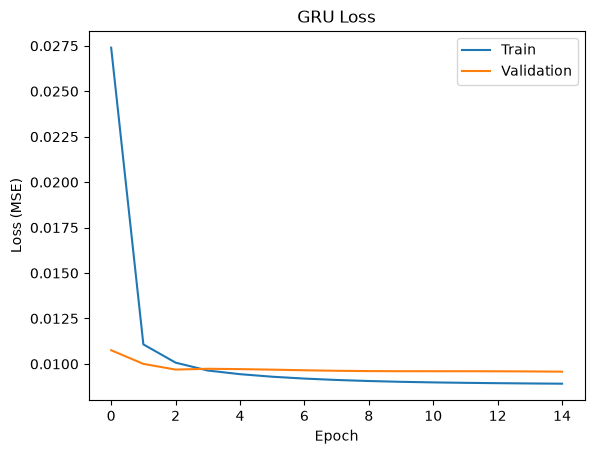

In [96]:
plt.plot(gru_history.history['loss'], label='Train')
plt.plot(gru_history.history['val_loss'], label='Validation')
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("GRU Loss")
plt.legend()
plt.show()

**Interpretation**
- Both losses drop in the first epochs and then become almost flat.
- Train and validation loss stay close, so the model is not overfitting.

In [97]:
gru_pred_scaled = gru_model.predict(X_seq_test)
gru_pred = temp_scaler.inverse_transform(gru_pred_scaled) 

22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


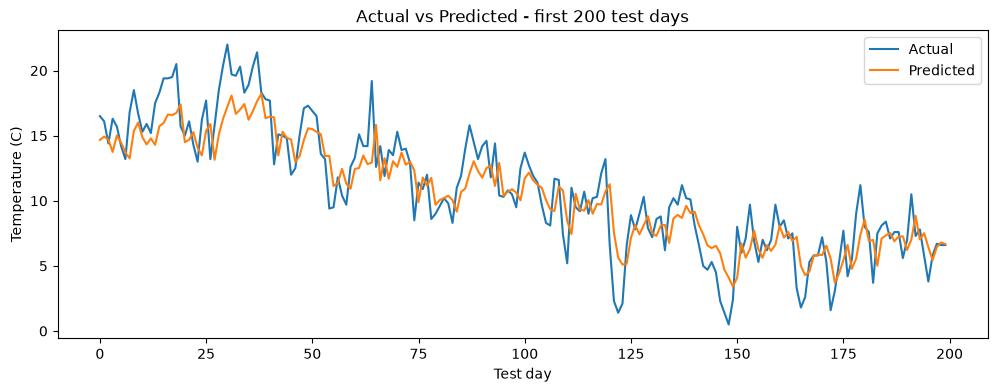

In [98]:
days = 200

plt.figure(figsize=(12, 4))
plt.plot(y_test_actual[:days], label='Actual')
plt.plot(gru_pred[:days], label='Predicted') 
plt.xlabel("Test day")
plt.ylabel("Temperature (C)")
plt.title("Actual vs Predicted - first " + str(days) + " test days")
plt.legend()
plt.show()

**Interpretation**
- The predicted line follows the up and down movement of the actual line.
- It is smoother than the actual line and misses sudden jumps, because daily temperature is noisy.

In [99]:
gru_rmse = np.sqrt(mean_squared_error(y_test_actual, gru_pred))
gru_mae = mean_absolute_error(y_test_actual, gru_pred)

results = pd.DataFrame({
    'Model': ['GRU', 'Naive baseline'],
    'RMSE (C)': [round(gru_rmse, 3), round(naive_rmse, 3)],
    'MAE (C)': [round(gru_mae, 3), round(naive_mae, 3)]
})

results

,Model,RMSE (C),MAE (C)
0,GRU,2.309,1.828
1,Naive baseline,2.486,1.951


In [100]:
if gru_rmse < naive_rmse:
    print("The GRU beat the naive baseline.")
else:
    print("The GRU did not beat the naive baseline.")

The GRU beat the naive baseline.


**Interpretation**
- RMSE is the typical error in degrees Celsius, and MAE is the average error in degrees Celsius.
- The GRU error is in the normal 2 to 3 C range for this noisy data.
- The GRU gives a small improvement over the naive baseline, as expected for daily temperature.

### Bonus: LSTM instead of GRU

In [101]:
from tensorflow.keras.layers import LSTM

set_random_seed(seed)

lstm_model = Sequential()
lstm_model.add(Input(shape=(look_back, 1)))
lstm_model.add(LSTM(32, activation='tanh'))
lstm_model.add(Dense(1))

lstm_model.compile(optimizer='adam', loss='mse')

In [102]:
lstm_history = lstm_model.fit(X_seq_train, y_seq_train,
                              epochs=epochs,
                              batch_size=batch_size,
                              validation_split=0.1,
                              verbose=0)

In [103]:
lstm_pred = temp_scaler.inverse_transform(lstm_model.predict(X_seq_test))

lstm_rmse = np.sqrt(mean_squared_error(y_test_actual, lstm_pred))
lstm_mae = mean_absolute_error(y_test_actual, lstm_pred)

bonus = pd.DataFrame({
    'Model': ['GRU', 'LSTM', 'Naive baseline'],
    'RMSE (C)': [round(gru_rmse, 3), round(lstm_rmse, 3), round(naive_rmse, 3)],
    'MAE (C)': [round(gru_mae, 3), round(lstm_mae, 3), round(naive_mae, 3)]
})

bonus

22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


,Model,RMSE (C),MAE (C)
0,GRU,2.309,1.828
1,LSTM,2.286,1.802
2,Naive baseline,2.486,1.951


**Interpretation**
- GRU and LSTM give almost the same error, so the lighter GRU is enough for this data.

## 4.4 Save and Reflect

In [104]:
gru_model.save('models/rnn_temperature_model.h5')

**Reflection**
- A SimpleRNN passes one hidden state forward and forgets old information quickly. A GRU adds two gates: the update gate decides how much old memory to keep, and the reset gate decides how much old memory to use for the new step. So the GRU remembers longer patterns.
- The scaler was fitted on the training data only, because the test data is the "future". Using its min and max would leak future information into training.
- RMSE and MAE are both errors in degrees Celsius. RMSE gives extra weight to big mistakes, while MAE is the plain average mistake. Compare the GRU and the naive rows in the table above to see if the model beat the baseline.

# Step 5: Transformers - Fill-Mask, Question Answering and Text Generation

## 5.1 Setup and Fill-Mask

In [105]:
%pip install -q transformers torch

Note: you may need to restart the kernel to use updated packages.


In [106]:
from transformers import pipeline, set_seed

unmasker = pipeline('fill-mask', model='distilbert-base-uncased')

C:\Users\DELL\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Device set to use cpu


In [107]:
mask_sentences = [
    "The capital of India is [MASK].",
    "The Taj Mahal is located in [MASK].",
    "ISRO is the space [MASK] of India.",
    "Mumbai is the financial capital of [MASK].",
    "My favourite Indian food is [MASK]."
]

In [108]:
for sentence in mask_sentences:
    print(sentence)
    results = unmasker(sentence, top_k=3)
    for r in results:
        print("    ", r['token_str'], "->", round(r['score'], 4))
    print()

The capital of India is [MASK].
     pune -> 0.1559
     bangalore -> 0.1475
     mumbai -> 0.0778

The Taj Mahal is located in [MASK].
     agra -> 0.1567
     delhi -> 0.1276
     lahore -> 0.1089

ISRO is the space [MASK] of India.
     agency -> 0.4789
     arm -> 0.0482
     corporation -> 0.0405

Mumbai is the financial capital of [MASK].
     india -> 0.4679
     maharashtra -> 0.3216
     mumbai -> 0.094

My favourite Indian food is [MASK].
     chicken -> 0.1436
     curry -> 0.0642
     vegetarian -> 0.0462



**Interpretation**
- The score shows how sure the model is. For clear facts (capital, location) the top answer usually has a much higher score than the others.
- The last sentence has many valid answers, so the top 3 scores are close and low. The model is not sure because many foods are correct.

## 5.2 Question Answering

In [109]:
from transformers import pipeline

qa = pipeline('question-answering', model='distilbert-base-cased-distilled-squad')

Device set to use cpu


In [110]:
paragraphs = [
    "The Indian Space Research Organisation, or ISRO, is the space agency of India. It was formed in 1969 and its headquarters are in Bengaluru. ISRO launched the Chandrayaan-3 mission in 2023, and its lander touched down near the south pole of the Moon. The agency also built the Mars Orbiter Mission, which reached Mars orbit in 2014.",
    "The Taj Mahal is a white marble mausoleum in Agra, a city in the state of Uttar Pradesh. It was built by the Mughal emperor Shah Jahan in memory of his wife Mumtaz Mahal. Construction started in the early 1630s and the main tomb was finished around 1643. The monument stands on the bank of the Yamuna river and is a UNESCO World Heritage Site.",
    "Indian Railways is the national railway system of India and is owned by the Government of India. It is one of the largest railway networks in the world, with a route length of over 65,000 kilometres. The first passenger train in India ran in 1853 between Bombay and Thane. Every day, millions of passengers travel on its trains.",
    "The Unified Payments Interface, or UPI, is an instant payment system developed by the National Payments Corporation of India. It was launched in 2016 and lets people send money directly between bank accounts using a mobile phone. Users can pay with a simple UPI ID or by scanning a QR code. UPI is now used for billions of transactions every month across India.",
    "Mumbai is the capital city of the state of Maharashtra and the financial capital of India. It is located on the west coast of the country, along the Arabian Sea. The city was earlier known as Bombay, and its name was officially changed in 1995. Mumbai is also home to the Hindi film industry, popularly called Bollywood."
]

In [111]:
questions = [
    "Where is the headquarters of ISRO?",
    "Which mission reached the orbit of Mars in 2014?",
    "Who built the Taj Mahal?",
    "How tall is the main dome of the Taj Mahal?",
    "When did the first passenger train run in India?",
    "Between which two cities did the first passenger train run?",
    "Which organisation developed UPI?",
    "In which year was UPI launched?",
    "Along which sea is Mumbai located?",
    "What was Mumbai earlier called?"
]

paragraph_ids = [0, 0, 1, 1, 2, 2, 3, 3, 4, 4]

expected = ["Bengaluru", "Mars Orbiter Mission", "Shah Jahan", "", "1853",
            "Bombay", "National Payments Corporation of India", "2016", "Arabian Sea", "Bombay"]

In [112]:
import pandas as pd
rows = []

for i in range(len(questions)):
    output = qa(question=questions[i], context=paragraphs[paragraph_ids[i]])
    answer = output['answer']
    score = round(output['score'], 4)

    if expected[i] != "" and expected[i].lower() in answer.lower():
        correct = "Yes"
    else:
        correct = "No"

    rows.append([questions[i], answer, score, correct])

qa_df = pd.DataFrame(rows, columns=['Question', 'Predicted_Answer', 'Confidence_Score', 'Correct'])
qa_df

,Question,Predicted_Answer,Confidence_Score,Correct
0,Where is the headquarters of ISRO?,Bengaluru,0.9749,Yes
1,Which mission reached the orbit of Mars in 2014?,Mars Orbiter Mission,0.8328,Yes
2,Who built the Taj Mahal?,Mughal emperor Shah Jahan,0.6112,Yes
3,How tall is the main dome of the Taj Mahal?,white marble,0.7592,No
4,When did the first passenger train run in India?,1853,0.9937,Yes
5,Between which two cities did the first passeng...,Bombay and Thane,0.9666,Yes
6,Which organisation developed UPI?,National Payments Corporation of India,0.7617,Yes
7,In which year was UPI launched?,2016,0.9976,Yes
8,Along which sea is Mumbai located?,Arabian Sea,0.7811,Yes
9,What was Mumbai earlier called?,Bombay,0.9875,Yes


In [113]:
correct_count = (qa_df['Correct'] == 'Yes').sum()
print("Correct answers:", correct_count, "out of", len(qa_df))

Correct answers: 9 out of 10


In [114]:
unanswerable = qa_df.iloc[3]
print("Question :", unanswerable['Question'])
print("Answer   :", unanswerable['Predicted_Answer'])
print("Score    :", unanswerable['Confidence_Score'])

Question : How tall is the main dome of the Taj Mahal?
Answer   : white marble
Score    : 0.7592


**Interpretation**
- The Correct column is filled by comparing each answer with the expected answer written above, so please also read the table once yourself.
- Most answers are short phrases copied from the paragraph.
- For the unanswerable question the model still returns some phrase, because this model always picks a span and cannot say "no answer". Its score is usually low, which is the warning sign.

### Hinglish question

In [115]:
hinglish = qa(question="ISRO ka headquarters kahan hai?", context=paragraphs[0])
print("Answer:", hinglish['answer'])
print("Score :", round(hinglish['score'], 4))

Answer: Bengaluru
Score : 0.865


**Interpretation**
- The model was trained on English, so a Hinglish question is harder. Check whether the answer is still Bengaluru and compare its score with the English version of the same question.

## 5.3 Text Generation

In [116]:
gen = pipeline('text-generation', model='distilgpt2')
set_seed(seed)

Device set to use cpu


In [117]:
prompts = ["India is a country where", "Deep learning is", "The Indian Railways is"]

In [118]:
for prompt in prompts:
    outputs = gen(prompt, max_new_tokens=30, do_sample=True, num_return_sequences=2,
                  pad_token_id=gen.tokenizer.eos_token_id)
    print("Prompt:", prompt)
    for out in outputs:
        print("   ->", out['generated_text'])
    print()

Prompt: India is a country where
   -> India is a country where more than 3 percent of people are working and we have a great opportunity to help improve our lives and our health.





And
   -> India is a country where there was no threat to Israel from a missile strike. The recent Israeli missile strike in Gaza made it seem that the US and Israeli authorities were being prepared

Prompt: Deep learning is
   -> Deep learning is a new feature of the web. All we have to do is learn what's going on in Web programming.




The Web is
   -> Deep learning is a huge thing. It’s amazing.”

Prompt: The Indian Railways is
   -> The Indian Railways is currently offering a free 4-day free ride to train passengers in the country's five largest cities, despite the fact that the trains are not running.
   -> The Indian Railways is currently working on the project of converting a massive train of railway to a modern, modern and efficient platform to its historic purpose.








### Temperature: 0.5 vs 1.5

In [119]:
for temp in [0.5, 1.5]:
    outputs = gen(prompts[0], max_new_tokens=30, do_sample=True, temperature=temp,
                  num_return_sequences=2, pad_token_id=gen.tokenizer.eos_token_id)
    print("Temperature:", temp)
    for out in outputs:
        print("   ->", out['generated_text'])
    print()

Temperature: 0.5
   -> India is a country where the poor are forced to pay more than the rich.



















   -> India is a country where there are many people with different backgrounds and backgrounds. But it is not for the sake of the people who are trying to change the way we live.

Temperature: 1.5
   -> India is a country where people have access to government institutions."




This is the kind of thing that a certain portion of us who enjoy to think it's important
   -> India is a country where a long-standing rule has not been held true for the foreseeable future [that country becomes economically neutral], which is just one big policy development project."



**Interpretation**
- Low temperature (0.5) gives safe and repeated text that follows the most likely words.
- High temperature (1.5) gives more creative text, but it can become random and may lose meaning.
- distilgpt2 is a small model, so even the good outputs can be off-topic or wrong.

## 5.4 Visualise and Reflect

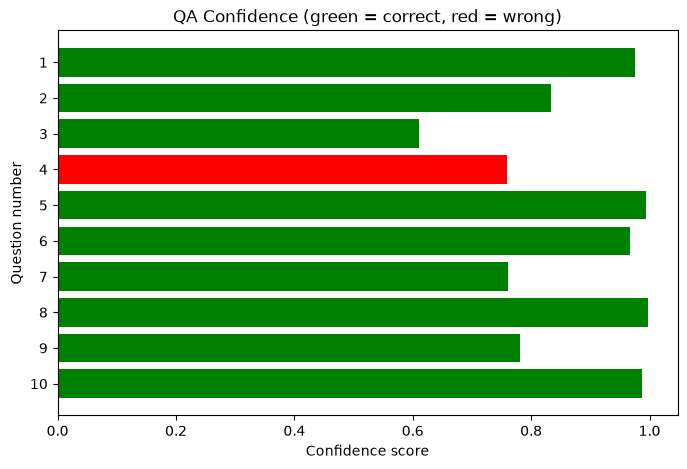

In [120]:
colours = []

for value in qa_df['Correct']:
    if value == 'Yes':
        colours.append('green')
    else:
        colours.append('red')

question_numbers = range(1, len(qa_df) + 1)

plt.figure(figsize=(8, 5))
plt.barh(question_numbers, qa_df['Confidence_Score'], color=colours)
plt.gca().invert_yaxis()
plt.yticks(question_numbers)
plt.xlabel("Confidence score")
plt.ylabel("Question number")
plt.title("QA Confidence (green = correct, red = wrong)")
plt.show()

**Interpretation**
- Green bars (correct answers) usually have high confidence.
- Red bars (wrong answers), including the unanswerable question, usually have lower confidence.

**Reflection**
- Encoder (BERT-style) reads the whole sentence in both directions, so it is good for understanding tasks like fill-mask and QA. Decoder (GPT-style) reads left to right and predicts the next word, so it is good for generating text.
- Self-attention lets every word look at all other words in the sentence and decide which ones matter most for its meaning.
- Extractive QA means the answer is a piece of text copied from the paragraph. The model does not write a new answer.
- Temperature controls randomness: low values pick the most likely words, high values allow more surprising words.
- Generated text can sound fluent but be wrong, because the model learns which words usually follow each other, not whether a fact is true.
- The Hinglish question shows that an English-trained model can struggle with mixed-language input.

# Step 6: Comparison and Reflection

## 6.1 Results Summary Table

In [121]:
time_taken = ["45 min", "50 min", "55 min", "50 min", "45 min"]

summary = pd.DataFrame({
    'Step / Topic': ['ANN', 'OpenCV', 'CNN', 'RNN', 'Transformer'],
    'Task type': ['Multi-class Classification', 'Preprocessing & Detection', 'Classification',
                  'Time-series Regression', 'Inference'],
    'Dataset used': ['Wine - ' + str(len(df)) + ' wines',
                     str(len(images)) + ' images',
                     'MNIST - ' + str(train_samples) + ' train, ' + str(test_samples) + ' test',
                     'Melbourne temperature - ' + str(len(temp_df)) + ' days',
                     str(len(paragraphs)) + ' paragraphs, ' + str(len(questions)) + ' questions'],
    'Key metric': ['Accuracy', 'N/A (faces detected)', 'Accuracy', 'RMSE', 'Accuracy (manually checked)'],
    'Result achieved': [str(round(ann_test_accuracy * 100, 2)) + " %",
                        str(sum(face_counts)) + " face(s) found",
                        "CNN " + str(round(cnn_acc * 100, 2)) + " % / ANN " + str(round(ann_acc * 100, 2)) + " %",
                        str(round(gru_rmse, 2)) + " C",
                        str(correct_count) + " / " + str(len(qa_df)) + " correct"],
    'Time taken': time_taken
})

summary

,Step / Topic,Task type,Dataset used,Key metric,Result achieved,Time taken
0,ANN,Multi-class Classification,Wine - 178 wines,Accuracy,94.44 %,45 min
1,OpenCV,Preprocessing & Detection,5 images,N/A (faces detected),1 face(s) found,50 min
2,CNN,Classification,"MNIST - 20000 train, 4000 test",Accuracy,CNN 97.28 % / ANN 95.45 %,55 min
3,RNN,Time-series Regression,Melbourne temperature - 3650 days,RMSE,2.31 C,50 min
4,Transformer,Inference,"5 paragraphs, 10 questions",Accuracy (manually checked),9 / 10 correct,45 min


## 6.2 Written Reflection

- **Most challenging step:** Step 4 (RNN), because the data must be split, scaled and cut into 30-day sequences in the correct order without leaking test data.
- **Best result for the effort:** The ANN on the Wine data gave very high accuracy with a few lines of code and very little training time.
- **One change to the ANN:** With more time I would add Dropout and use cross-validation, because the test set has only 36 wines and one error changes the score a lot.
- **CNN vs ANN parameters:** The CNN reuses small shared filters, so it needs about half the parameters of the ANN. Fewer parameters mean faster training, less memory and less overfitting.
- **GRU vs Transformer:** A GRU reads the sequence one step at a time and keeps a memory (recurrence). A Transformer looks at all positions at once using attention, so it handles long text better and trains in parallel.
- **GPT-style wrong facts:** It predicts likely words, not true facts. Before using it in a product I would add fact checking against a trusted source, human review, and filters for unsafe content.
- **Haar cascade today:** It is still useful on small devices or old hardware where a fast, light, no-training face detector is needed.

# Final Interpretation

- **ANN:** A small network reached high accuracy on the Wine data after scaling the features.
- **OpenCV:** HSV masks, morphology and Sobel edges worked without any training, and the Haar cascade found the real face.
- **CNN:** The CNN was more accurate than the ANN on MNIST with about half the parameters.
- **RNN:** The GRU followed the yearly temperature pattern and gave a small improvement over the naive baseline.
- **Transformers:** Pre-trained models answered questions and generated text without any training, but they can still be wrong and need checking.